# IRC Data Cleaning

:::{div}
:class: colab-badge
[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/blinkletter/UsingPsi4/blob/main/book/10-Solvent/102-IRCData.ipynb)
:::

As **discussed** in the [previous notebook](101-Solvent.ipynb), we followed the IRC in gas phase and then calculated the energy in water at every point along the path. That left us with three files.

| Files | Description |
| :--------------------------- | :------------------------- |
| `sn2_gas_irc_forward.xyz` & `sn2_gas_irc_backward.xyz` | The gas phase IRC, one file for each direction |
| `sn2_water_path_B3LYP321G.json` | The energy in water (*ddX* solvent model) of every structure on that path |

Each trajectory file holds one **frame** for each point on the path. A frame is the number of atoms, a title line with the step number and the energy, and one line for each atom with its *x*, *y* and *z* coordinates. Both files **start** with the transition state (step 0). The coordinates are in **Bohr**.

In the *GAMESS* book, I used *grep* to pull eight little text files out of each pair of enormous log files: the path distance, the energy, and the two C&ndash;Cl distances, each with its own quirks (some files included step zero and some did not, and the energy of the transition state had to be found by hand). Our files are tidier, but there is still **cleaning** to do. We must pick the numbers out of the text, convert units, calculate the bond lengths, flip the sign of the path distance for the backward run, remove the duplicate transition state, stitch the two directions together and finally **join** the water energies to the gas phase path.

This notebook does not run *Psi4*, so the hidden first cell only imports *NumPy*, *pandas* and *Matplotlib* and applies the plot style sheet.

In [1]:
####################################################
### Import Libraries and set up global variables ###
####################################################

from pathlib import Path

try:
    import google.colab
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

# Standard imports
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Plot style sheets from the book's GitHub repository
if IN_COLAB and not Path("styles/tufte.mplstyle").exists():
    !wget -q -P styles https://raw.githubusercontent.com/blinkletter/UsingPsi4/main/styles/tufte.mplstyle
    !wget -q -P styles https://raw.githubusercontent.com/blinkletter/UsingPsi4/main/styles/S2_classic2.mplstyle

if IN_COLAB:
    plt.style.use("styles/tufte.mplstyle")
else:
    plt.style.use("../../styles/tufte.mplstyle")

## Importing Raw Data

We could have **edited** the data in a text editor, but we will do everything using the data analysis tools of *Python* and *pandas*. The data files must be in the same directory as this notebook, or you must specify the file path. If you did not run the previous notebook (on *Google Colab*, for example), we will download my copy of the files from the book's *GitHub* repository. Don't worry, *Python* will scream at you if you make a mistake and you will be able to **fix any problems**.

We will also need two **conversion factors**. This notebook does not import *Psi4*, so we type in the same values that `psi4.constants` uses.

In [2]:
from urllib.request import urlopen

url = "https://raw.githubusercontent.com/blinkletter/UsingPsi4/main/book/10-Solvent/"

def read_lines(filename):
    if Path(filename).exists():
        with open(filename) as f:
            return f.read().splitlines()
    with urlopen(url + filename) as f:
        return f.read().decode().splitlines()

bohr2angstroms = 0.52917721067     # Angstrom per Bohr
hartree2kJmol = 2625.499639        # kJ/mol per Hartree
step_size = 0.3                    # irc_step_size used in the calculations

lines = read_lines("sn2_gas_irc_forward.xyz")
print(len(lines), "lines in the file")
print("\n".join(lines[:9]))

104 lines in the file
6
IRC trajectory step: 0. E: -955.7760220892411
Cl     0.000000    -4.503104    -0.000002
Cl     0.000000     4.503104    -0.000002
C     0.000000     0.000000     0.000013
H     0.000000     0.000000     2.028765
H     1.756949     0.000000    -1.014375
H    -1.756949     0.000000    -1.014375
6


| Line | Notes |
| :---- | :---- |
| `from urllib.request import urlopen` | A function that opens a file on the internet as if it were on our computer. |
| `def read_lines(filename):` | Reads a file and returns a **list of its lines**. If the file is in this folder we open it, otherwise we download it from `url` + `filename`. |
| `f.read().splitlines()` | Reads the whole file as one long text and cuts it into lines. |
| `.decode()` | A downloaded file arrives as raw bytes. `decode()` turns them into text. |
| `bohr2angstroms`, `hartree2kJmol` | The conversion factors. *GAMESS* users (me) have been multiplying by 2625.5 for years. |
| `step_size = 0.3` | The distance between points on the path, which we chose with `irc_step_size` in the previous notebook. |
| `print("\n".join(lines[:9]))` | Shows the first frame: the number of atoms, the title line and the six atoms. |

[[Describe the first frame as printed: title format, coordinates in Bohr.]]

## Cleaning the Data

Data cleaning is **half the work** in data analysis. We need to pick out the records we want and drop everything else. In the *GAMESS* book, *grep* picked out every line that contained a given piece of text. In *Python*, a **list comprehension** with an `if` does the same job. We want three kinds of lines: the title lines (step and energy), the chlorine lines and the carbon lines.

In [3]:
titles = [line for line in lines if "IRC" in line]
chlorines = [line for line in lines if line.split() and line.split()[0].upper() == "CL"]
carbons = [line for line in lines if line.split() and line.split()[0].upper() == "C"]

print(len(titles), "title lines,", len(chlorines), "chlorine lines,", len(carbons), "carbon lines")
print(titles[0])
print(chlorines[0])
print(carbons[0])

13 title lines, 26 chlorine lines, 13 carbon lines
IRC trajectory step: 0. E: -955.7760220892411
Cl     0.000000    -4.503104    -0.000002
C     0.000000     0.000000     0.000013


| Line | Notes |
| :---- | :---- |
| `[line for line in lines if "IRC" in line]` | Every line that contains the text `IRC`. Only the title lines do. This is our *grep*. |
| `line.split()` | Cuts a line into words wherever there are spaces. An empty line gives an empty list, which counts as **false**, so `line.split() and ...` skips empty lines. |
| `line.split()[0].upper() == "CL"` | The first word is the element symbol. `.upper()` turns `Cl` into `CL`, so the test works whichever way *Psi4* wrote it. |

There are two chlorine lines for each title line, Cl1 and then Cl2, and one carbon line. [[Check counts: titles = carbons = chlorines/2.]]

Now we turn the title lines into a *pandas* **dataframe**. Splitting each line into words gives us a list of words, and a list of lists becomes a table.

In [4]:
df = pd.DataFrame([line.split() for line in titles])
display(df.head(3))

,0,1,2,3,4,5
0,IRC,trajectory,step:,0.,E:,-955.7760220892411
1,IRC,trajectory,step:,1.,E:,-955.7760971217979
2,IRC,trajectory,step:,2.,E:,-955.7763060688446


Inspecting the dataframe shows me that I only need **two** of the columns: column 3 is the step number and column 5 is the energy. [[Confirm column numbers from output.]] In the code below I create a new dataframe by **selecting** those columns out of the previous dataframe, convert them from text to numbers and **rename** them so I don't forget what they are. Then I calculate the distance along the path, the **stride**.

In [5]:
energy = df[[3, 5]].astype(float)
energy = energy.rename({3: "step", 5: "energy gas"}, axis="columns")
energy["stride"] = energy["step"].abs() * step_size
display(energy.head(3))

,step,energy gas,stride
0,0.0,-955.776022,0.0
1,1.0,-955.776097,0.3
2,2.0,-955.776306,0.6


| Line | Notes |
| :---- | :---- |
| `df[[3, 5]]` | A new dataframe with only columns 3 and 5. |
| `.astype(float)` | The words are still **text**. This converts them to numbers. `'1.'` becomes `1.0`. |
| `.rename({3: "step", 5: "energy gas"}, axis="columns")` | Gives the columns names instead of numbers. We say "gas" because the water energies will join them later. |
| `energy["step"].abs() * step_size` | The distance along the path in amu<sup>&frac12;</sup> bohr. `.abs()` makes the step number positive. We will give the backward direction its **minus sign** ourselves, later, whatever sign *Psi4* used. |

### More Cleaning

Next, the bond lengths. We split each atom line into words, keep words 1 to 3 (the *x*, *y* and *z* coordinates), convert them to numbers and then to &Aring;ngstroms. The chlorine lines alternate, Cl1, Cl2, Cl1, Cl2&hellip;, so we **deal them out** like cards into two piles.

In [6]:
cl = pd.DataFrame([line.split()[1:4] for line in chlorines]).astype(float) * bohr2angstroms
c = pd.DataFrame([line.split()[1:4] for line in carbons]).astype(float) * bohr2angstroms

cl1 = cl.iloc[0::2].reset_index(drop=True)
cl2 = cl.iloc[1::2].reset_index(drop=True)

bonds = pd.DataFrame()
bonds["C-Cl1"] = np.sqrt(((cl1 - c) ** 2).sum(axis=1))
bonds["C-Cl2"] = np.sqrt(((cl2 - c) ** 2).sum(axis=1))
display(bonds.head(3))

,C-Cl1,C-Cl2
0,2.382940,2.382940
1,2.333680,2.432835
2,2.284853,2.483073


| Line | Notes |
| :---- | :---- |
| `line.split()[1:4]` | Words 1, 2 and 3 of an atom line: the coordinates. Word 0 is the symbol. |
| `* bohr2angstroms` | Multiplies **every** number in the dataframe by the conversion factor. |
| `cl.iloc[0::2]` | Every second row, starting with row 0: the Cl1 lines. `cl.iloc[1::2]` starts with row 1: the Cl2 lines. |
| `.reset_index(drop=True)` | Renumbers the rows 0, 1, 2&hellip; so that row *n* of each dataframe belongs to frame *n*. |
| `cl1 - c` | *pandas* subtracts the two dataframes **row by row and column by column**, which matches up the same frame and the same coordinate. |
| `np.sqrt(((cl1 - c) ** 2).sum(axis=1))` | Pythagoras: square the differences in *x*, *y* and *z*, add them across each row (`axis=1`) and take the square root. That is the C&ndash;Cl distance for every frame at once. |

[[First C-Cl1 and C-Cl2 values should equal the TS bond lengths from 101.]]

### Rinse and Repeat

We must **repeat** all of this for the backward file. Rather than copy and paste the code, let us collect the steps above into one **function**. Then we can call it with any file name.

In [7]:
def read_irc_table(filename):
    lines = read_lines(filename)
    titles = [line for line in lines if "IRC" in line]
    chlorines = [line for line in lines if line.split() and line.split()[0].upper() == "CL"]
    carbons = [line for line in lines if line.split() and line.split()[0].upper() == "C"]

    df = pd.DataFrame([line.split() for line in titles])
    table = df[[3, 5]].astype(float)
    table = table.rename({3: "step", 5: "energy gas"}, axis="columns")
    table["stride"] = table["step"].abs() * step_size

    cl = pd.DataFrame([line.split()[1:4] for line in chlorines]).astype(float) * bohr2angstroms
    c = pd.DataFrame([line.split()[1:4] for line in carbons]).astype(float) * bohr2angstroms
    cl1 = cl.iloc[0::2].reset_index(drop=True)
    cl2 = cl.iloc[1::2].reset_index(drop=True)
    table["C-Cl1"] = np.sqrt(((cl1 - c) ** 2).sum(axis=1))
    table["C-Cl2"] = np.sqrt(((cl2 - c) ** 2).sum(axis=1))
    return table

forward = read_irc_table("sn2_gas_irc_forward.xyz")
backward = read_irc_table("sn2_gas_irc_backward.xyz")

print(len(forward), "forward points,", len(backward), "backward points")
display(backward.head(3))

13 forward points, 8 backward points


,step,energy gas,stride,C-Cl1,C-Cl2
0,0.0,-955.776022,0.0,2.382940,2.382940
1,-1.0,-955.776097,0.3,2.432835,2.333680
2,-2.0,-955.776306,0.6,2.483073,2.284853


| Line | Notes |
| :---- | :---- |
| `def read_irc_table(filename):` | Everything from the cells above, in one place. It returns one table with the step, energy, stride and both C&ndash;Cl distances. |
| `table["C-Cl1"] = ...` | This time we put the bond lengths straight into the same table. |

[[Number of points in each direction.]]

## Collate the Path

Now we join the two directions into one path. We will need to **invert** the sign of the stride (reaction progress) for the **backward data**, so that the path runs from negative values, through the transition state at zero, to positive values. Both files start with the transition state, so we **drop** it from the backward table, or it would appear twice. Then we **append** one table to the other, **sort** the rows by stride and reset the index.

In [8]:
backward["stride"] = backward["stride"] * (-1)
backward = backward[backward["stride"] != 0]

data = pd.concat([backward, forward])
data = data.sort_values(by=["stride"])
data.reset_index(drop=True, inplace=True)
data["stride"] = data["stride"].round(2)

display(data)

/var/folders/_0/pb9y62rd59n_3vs7rbl1bndm0000gn/T/ipykernel_92479/1684570122.py:6: Pandas4Warning: The inplace keyword in DataFrame.reset_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  data.reset_index(drop=True, inplace=True)


,step,energy gas,stride,C-Cl1,C-Cl2
0,-7.0,-955.776342,-2.1,2.662074,2.126510
1,-6.0,-955.776342,-1.8,2.662074,2.126510
2,-5.0,-955.777198,-1.5,2.636936,2.146260
3,-4.0,-955.776924,-1.2,2.584843,2.189704
4,-3.0,-955.776602,-0.9,2.533626,2.236581
5,-2.0,-955.776306,-0.6,2.483073,2.284853
6,-1.0,-955.776097,-0.3,2.432835,2.333680
7,0.0,-955.776022,0.0,2.382940,2.382940
8,1.0,-955.776097,0.3,2.333680,2.432835
9,2.0,-955.776306,0.6,2.284853,2.483073


| Line | Notes |
| :---- | :---- |
| `backward["stride"] * (-1)` | **Reverses** the progress for the backward IRC. |
| `backward[backward["stride"] != 0]` | Keeps only the rows whose stride is **not** zero. That drops the transition state from the backward table. (In the *GAMESS* notebook I dropped it by its row number with `df_r.drop(index=[0])`. This way we do not have to know where it is.) |
| `pd.concat([backward, forward])` | Stacks the two tables, one on top of the other. |
| `data.sort_values(by=["stride"])` | Sorts the rows from the most negative stride to the most positive. |
| `reset_index(drop=True, inplace=True)` | Renumbers the rows 0, 1, 2&hellip; in their new order. |
| `data["stride"].round(2)` | Rounds the strides to two decimal places. 3 &times; 0.3 is `0.8999999999999999` to a computer, and we are about to **match** these numbers with the strides in the water file. Rounding makes sure that 0.9 meets 0.9. |

[[Range of strides.]]

## Adding the Water Energies

The previous notebook saved the water energies, one for each point on the path, with the same strides. Now we **join** them to our table. The *pandas* `merge()` method lines up the rows of two tables by the values in a column that they share, here the stride.

In [9]:
water_file = "sn2_water_path_B3LYP321G.json"
if Path(water_file).exists():
    water = pd.read_json(water_file)
else:
    water = pd.read_json(url + water_file)
water["stride"] = water["stride"].round(2)
display(water.head(3))

data = data.merge(water, on="stride")

ts = data[data["stride"] == 0].iloc[0]
data["E gas (kJ/mol)"] = (data["energy gas"] - ts["energy gas"]) * hartree2kJmol
data["E water (kJ/mol)"] = (data["energy water"] - ts["energy water"]) * hartree2kJmol

display(data)

,stride,energy water,solvation
0,-2.1,-955.872007,-0.097124
1,-1.8,-955.872007,-0.097124
2,-1.5,-955.872376,-0.096549


,step,energy gas,stride,C-Cl1,C-Cl2,energy water,solvation,E gas (kJ/mol),E water (kJ/mol)
0,-7.0,-955.776342,-2.1,2.662074,2.126510,-955.872007,-0.097124,-0.840720,-9.209067
1,-6.0,-955.776342,-1.8,2.662074,2.126510,-955.872007,-0.097124,-0.840704,-9.209105
2,-5.0,-955.777198,-1.5,2.636936,2.146260,-955.872376,-0.096549,-3.087066,-10.178036
3,-4.0,-955.776924,-1.2,2.584843,2.189704,-955.871187,-0.095437,-2.367836,-7.056144
4,-3.0,-955.776602,-0.9,2.533626,2.236581,-955.870102,-0.094482,-1.523268,-4.208454
5,-2.0,-955.776306,-0.6,2.483073,2.284853,-955.869240,-0.093756,-0.745578,-1.943093
6,-1.0,-955.776097,-0.3,2.432835,2.333680,-955.868690,-0.093308,-0.196998,-0.499675
7,0.0,-955.776022,0.0,2.382940,2.382940,-955.868500,-0.093155,0.000000,0.000000
8,1.0,-955.776097,0.3,2.333680,2.432835,-955.868690,-0.093308,-0.196998,-0.499675
9,2.0,-955.776306,0.6,2.284853,2.483073,-955.869240,-0.093756,-0.745588,-1.944527


| Line | Notes |
| :---- | :---- |
| `pd.read_json(water_file)` | Reads the water energies: stride, energy in water and the solvation energy for every point. |
| `data.merge(water, on="stride")` | Joins the two tables. Each row of `data` gets the water columns from the row of `water` with the **same stride**. A row with no partner would be dropped, so check that the number of rows has not changed. |
| `data[data["stride"] == 0].iloc[0]` | The row of the transition state. |
| `(data["energy gas"] - ts["energy gas"]) * hartree2kJmol` | Every gas phase energy relative to the transition state, in kJ/mol. |
| `data["E water (kJ/mol)"]` | The same for the water energies, relative to the transition state **in water**. |

In the *GAMESS* notebook I subtracted the **highest** energy on the path. Here we subtract the energy of the transition state instead. In gas phase they are the same thing. In water, the gas phase transition state structure need not be the highest point on our path, so this way we can see if it is not. [[Check: number of rows after merge; is stride 0 the highest point in water?]]

### Documentation is Important

Take note of the **descriptions** for how I **converted** the text data files into dataframes and then **processed** them to create the table. This **documentation** is not a waste of time. Next week, I will have no memory of what I did. I will be able to **follow** my own work and trouble shoot any errors because of this documentation. Most importantly, others will be able to recognize my genius or **correct** my mistakes.

### Writing Data Files

Now that we have a set of processed data we should **write it out** so that we can **use it again** and again without having to repeat this whole processing procedure.

In [10]:
data.to_json("sn2_irc_B3LYP321G.json", orient="records", indent=2)

| Line | Notes |
| :---- | :---- |
| `data.to_json(..., orient="records", indent=2)` | Writes the table as a JSON file with one **record** for each point, and the column names stored with the numbers. |

## Plots

Below are some **quick** plots of various value pairs. They confirm that my data processing did not cause any disastrous misalignments of data series. They are just used for **diagnostic** purposes (I found some really big mistakes in the *GAMESS* version that showed up as crazy zig-zag plots before I figured all this out).

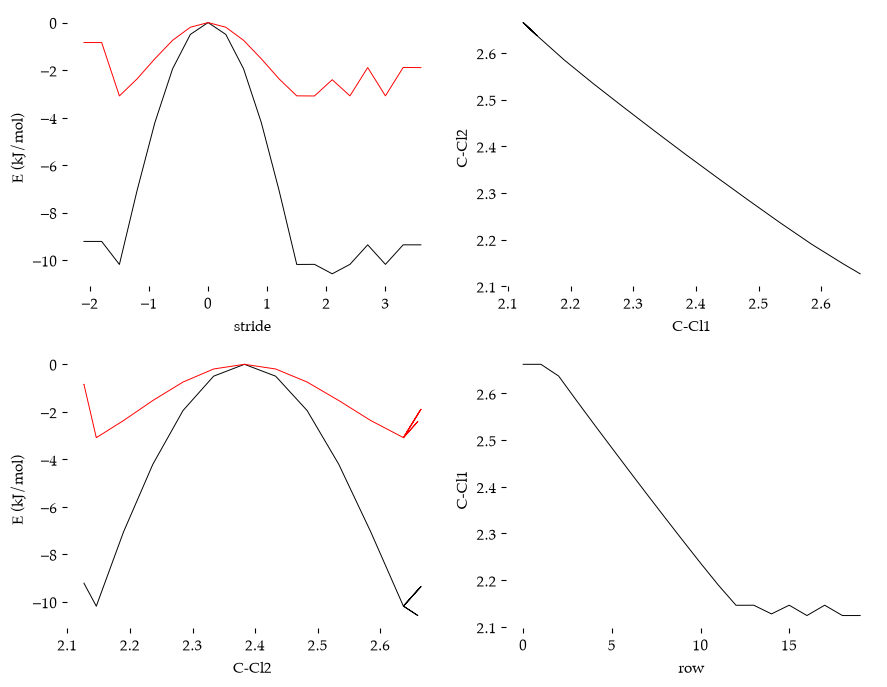

In [11]:
fig, axs = plt.subplots(nrows=2, ncols=2, figsize=(9,7))

axs[0, 0].plot(data["stride"], data["E water (kJ/mol)"], color="black", linewidth=0.7)
axs[0, 0].plot(data["stride"], data["E gas (kJ/mol)"], color="red", linewidth=0.7)
axs[0, 1].plot(data["C-Cl1"], data["C-Cl2"], color="black", linewidth=0.7)
axs[1, 0].plot(data["C-Cl2"], data["E water (kJ/mol)"], color="black", linewidth=0.7)
axs[1, 0].plot(data["C-Cl2"], data["E gas (kJ/mol)"], color="red", linewidth=0.7)
axs[1, 1].plot(data.index, data["C-Cl1"], color="black", linewidth=0.7)

axs[0, 0].set(xlabel="stride", ylabel="E (kJ/mol)")
axs[0, 1].set(xlabel="C-Cl1", ylabel="C-Cl2")
axs[1, 0].set(xlabel="C-Cl2", ylabel="E (kJ/mol)")
axs[1, 1].set(xlabel="row", ylabel="C-Cl1")
plt.show()

| Line | Notes |
| :---- | :---- |
| `plt.subplots(nrows=2, ncols=2, ...)` | Four plots in a 2 &times; 2 grid. `axs[0, 0]` is the top left one and `axs[1, 1]` the bottom right one. |
| `color="black"` / `color="red"` | Water energies in black and gas phase energies in red, as in my *GAMESS* plots. The bond lengths are the same for both, because the structures are the same. |
| `axs[0, 0].set(xlabel=..., ylabel=...)` | Sets several properties of a plot at once. |

[[Are all four smooth? Any zig-zags?]] I am leaving them here for your information. Please **proceed** to the next notebook to compare the data sets.

## You're Ready to Plot

We now have the **data table saved** as `sn2_irc_B3LYP321G.json`. We will use it in the [next notebook](103-IRCPlots.ipynb) where we will plot the data and see how much **difference** water makes.

```{warning} AI Statement
:class: dropdown
This page is an adaptation of the first "Solvent IRC Plots" notebook of my [previous web book on using *GAMESS*](https://blinkletter.github.io/UsingGAMESS). About [[a third]] of the text is **my own work**, carried over word for word or lightly edited, including the descriptions of importing, cleaning, collating, documenting and writing the data and the diagnostic plots. The **rest of the page** was written by an **LLM system** at my request. I asked it to read the IRC trajectory files written by *Psi4* instead of the *grep* extracts of the *GAMESS* log files, to calculate the bond lengths from the coordinates, and to join the water energies calculated along the gas phase path. The *Python* code, the line-by-line explanations of it and the commentary on the results were written by the LLM. The numbers quoted in the text come from my own calculations.
```